# 04 · Find the value: motor de recomendación de portafolios

**Fase: Find the value.** Convierte la señal en una herramienta que propone un portafolio para cada cliente y muestra la evidencia que lo respalda.

**La pregunta:** ¿qué decisión de inversión le recomendamos hoy (después del twist) a cada cliente?

**La solución:** un motor que, para cada cliente:
1. mide el riesgo **en su moneda base** (USD, COP o PEN),
2. aplica sus **restricciones** como reglas duras (caída máxima, límite por sector, alta volatilidad, diversificación),
3. usa un **retorno esperado prudente** (sin perseguir a los ganadores del año) que incluye el shock de tasas del twist,
4. optimiza según **su prioridad** (crecimiento, preservación o diversificación),
5. prueba la robustez del resultado con simulación y con el escenario del twist.

Usa las tablas limpias de `01_calidad_y_limpieza.ipynb` y los supuestos de `03_twist.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})

CLEAN = Path('../data_clean')
prices = pd.read_csv(CLEAN / 'prices_daily.csv', parse_dates=['date'])
macro = pd.read_csv(CLEAN / 'macro.csv', parse_dates=['date']).set_index('date')
ref = pd.read_csv(CLEAN / 'asset_reference.csv').set_index('asset_id')
clients = pd.read_csv(CLEAN / 'client_profiles.csv').set_index('client_id')

close = prices.pivot(index='date', columns='asset_id', values='close')
ASSETS = list(close.columns)
r_usd = close.pct_change().dropna()
rng = np.random.default_rng(7)

## 1. Supuestos del motor
Todos están en esta celda para poder cambiarlos y volver a correr.

| Supuesto | Valor | Por qué |
|---|---|---|
| Retorno esperado | 50% retorno histórico del activo + 50% promedio de todos | Con un solo año de datos, el retorno histórico es casi todo ruido; encogerlo hacia el promedio evita apostar todo a los ganadores del año |
| Ajuste por el twist de tasas | escala por sector × 3% (de `03_twist`) | La historia no permite estimar el efecto de +65 pb |
| Alta volatilidad | volatilidad anual > 30% | Para medir la restricción de CL_02 |
| Tope prudencial por activo | 35% (25% para CL_02) | Regla nuestra para no concentrar; no viene del perfil |
| Regla del twist | máx. 10% en A02 y A08 | Son los más expuestos a la subida de tasas; aplica a los tres clientes |
| Liquidez de CL_02 | 30% en efectivo o depósito en COP, retorno 0% | TW_02; no está en el dataset, retorno 0% es conservador |

In [2]:
SHRINK = 0.5
RATE_PCT_PER_POINT = 0.03
HIGH_VOL = 0.30
RATE_SCALE = pd.Series({'VF_A01': -1, 'VF_A02': -2, 'VF_A03': 0, 'VF_A04': 1,
                        'VF_A05': -1, 'VF_A06': -1, 'VF_A07': 0, 'VF_A08': -2})
FX_SHOCK = {'USD': 0.0, 'COP': 0.08, 'PEN': 0.0}   # TW_03: solo el COP
TWIST_CAP = 0.10                                   # máx. por activo muy sensible a tasas
RATE_SENSITIVE = RATE_SCALE.reindex(close.columns) <= -2

hist_ret = close.iloc[-1] / close.iloc[0] - 1
rate_shock = RATE_SCALE * RATE_PCT_PER_POINT
mu = SHRINK * hist_ret + (1 - SHRINK) * hist_ret.mean() + rate_shock
vol_usd = r_usd.std() * np.sqrt(252)
high_vol = vol_usd > HIGH_VOL

ref[['name', 'sector', 'country']].assign(
    retorno_histórico_pct=(hist_ret * 100).round(1),
    shock_tasas_pct=(rate_shock * 100).round(1),
    retorno_esperado_pct=(mu * 100).round(1),
    vol_anual_pct=(vol_usd * 100).round(1),
    alta_vol=high_vol,
)

,name,sector,country,retorno_histórico_pct,shock_tasas_pct,retorno_esperado_pct,vol_anual_pct,alta_vol
asset_id,,,,,,,,
VF_A01,Andes Consumer,Consumer Staples,Colombia,-10.0,-3.0,-11.8,20.1,False
VF_A02,Pacifica Digital,Technology,Peru,-13.8,-6.0,-16.7,45.2,True
VF_A03,Cordillera Energy,Energy,Colombia,-26.5,0.0,-17.1,34.9,True
VF_A04,Lima Financial,Financials,Peru,20.5,3.0,9.4,28.2,False
VF_A05,Aurora Health,Health Care,United States,31.9,-3.0,9.1,24.0,False
VF_A06,Norte Industrials,Industrials,Mexico,-22.4,-3.0,-18.0,33.5,True
VF_A07,Sierra Materials,Materials,Chile,-26.7,0.0,-17.2,38.3,True
VF_A08,Atlas Utilities,Utilities,United States,-14.2,-6.0,-16.9,15.4,False


Con este ajuste A05 sigue siendo el mejor, pero ya no rinde +32% esperado sino algo más prudente; A04 sube un poco por el beneficio de tasas altas.

## 2. Riesgo en la moneda de cada cliente
El retorno de un activo en USD visto desde COP o PEN es `(1 + r_USD) × (1 + Δ tipo de cambio) − 1`.

In [3]:
FX_SERIES = {'USD': pd.Series(0.0, index=macro.index), 'COP': macro.usd_cop.pct_change(), 'PEN': macro.usd_pen.pct_change()}

def local_returns(currency):
    fx = FX_SERIES[currency].reindex(r_usd.index)
    return (1 + r_usd).mul(1 + fx, axis=0) - 1

pd.DataFrame({cur: local_returns(cur).std() * np.sqrt(252) * 100 for cur in ['USD', 'COP', 'PEN']}).round(1).add_prefix('vol_anual_%_')

,vol_anual_%_USD,vol_anual_%_COP,vol_anual_%_PEN
asset_id,,,
VF_A01,20.1,20.3,20.1
VF_A02,45.2,45.0,44.8
VF_A03,34.9,35.6,35.2
VF_A04,28.2,29.2,28.4
VF_A05,24.0,24.9,24.4
VF_A06,33.5,33.9,33.5
VF_A07,38.3,39.1,38.6
VF_A08,15.4,16.4,15.5


## 3. El motor
1. Genera muchos portafolios al azar (pesos que suman 100%), mezclando portafolios concentrados y diversificados.
2. Descarta los que rompen alguna regla del cliente.
3. A los que quedan les calcula riesgo en la moneda del cliente: caída máxima, volatilidad, CVaR 95% (pérdida promedio del peor 5% de días) y peor resultado a 6 meses.
4. Elige el mejor según el objetivo del cliente.
5. Redondea los pesos a múltiplos de 5% para que sean presentables y vuelve a verificar las reglas.

In [4]:
COUNTRY = ref.loc[ASSETS, 'country'].values
SECTOR = ref.loc[ASSETS, 'sector'].values

def sample_weights(n):
    # alpha alto = pesos parejos, alpha bajo = portafolios concentrados
    return np.vstack([rng.dirichlet(np.full(len(ASSETS), a), n // 3) for a in (1.0, 0.4, 0.15)])

def risk_metrics(W, R):
    pr = R.values @ W.T
    curve = np.cumprod(1 + pr, axis=0)
    dd = (curve / np.maximum.accumulate(curve, axis=0) - 1).min(axis=0)
    vol = pr.std(axis=0) * np.sqrt(252)
    q = np.quantile(pr, 0.05, axis=0)
    cvar = np.where(pr <= q, pr, np.nan)
    cvar = np.nanmean(cvar, axis=0)
    worst6m = (curve[126:] / curve[:-126] - 1).min(axis=0)
    return dd, vol, cvar, worst6m

def rule_mask(W, rules):
    ok = (W <= rules['cap'] + 1e-9).all(axis=1)
    ok &= (W[:, RATE_SENSITIVE.values] <= TWIST_CAP + 1e-9).all(axis=1)
    if rules.get('high_vol_cap') is not None:
        ok &= W[:, high_vol.values].sum(axis=1) <= rules['high_vol_cap'] + 1e-9
    if rules.get('min_div'):
        k = rules['min_div']
        ok &= np.array([len(set(COUNTRY[w >= 0.10])) >= k and len(set(SECTOR[w >= 0.10])) >= k for w in W])
    return ok

def evaluate(W, rules):
    R = local_returns(rules['currency'])
    parts = [np.column_stack(risk_metrics(W[i:i + 10000], R)) for i in range(0, len(W), 10000)]
    dd, vol, cvar, worst6m = np.vstack(parts).T
    exp = W @ mu.values
    feasible = np.abs(dd) <= rules['dd_limit'] + 1e-9
    if rules.get('min_return') is not None:
        feasible &= exp >= rules['min_return']
    return pd.DataFrame({'caída_máx': dd, 'vol': vol, 'cvar95': cvar, 'peor_6m': worst6m,
                         'retorno_esperado': exp, 'factible': feasible})

def round_to_grid(w, step=0.05):
    total = w.sum()
    units = int(round(total / step))
    raw = w / step
    base = np.floor(raw)
    extra = units - int(base.sum())
    base[np.argsort(-(raw - base))[:extra]] += 1
    return base * step

def recommend(client_id, rules, n=None):
    n = n or rules.get('n_samples', 90000)
    cash = rules.get('cash', 0.0)
    W = sample_weights(n) * (1 - cash)
    W = W[rule_mask(W, rules)]
    res = evaluate(W, rules)
    score = {'return': res.retorno_esperado, 'sharpe': res.retorno_esperado / res.vol, 'min_cvar': res.cvar95}[rules['objective']]
    score = score.where(res.factible, -np.inf)
    # el redondeo puede romper una regla: se prueba con los mejores candidatos en orden
    order = np.argsort(-score.values)
    for i in order[:int(np.isfinite(score.values).sum())]:
        best = round_to_grid(W[i])
        best_res = evaluate(best[None, :], rules).iloc[0]
        if rule_mask(best[None, :], rules)[0] and best_res.factible:
            return pd.Series(best, ASSETS), best_res, res, W
    raise ValueError(f'{client_id}: ningún candidato cumple las reglas después de redondear')

## 4. Reglas y objetivo de cada cliente
Las reglas del perfil son obligatorias. El objetivo sale de la prioridad del cliente.

In [5]:
RULES = {
    'CL_01': dict(currency='USD', dd_limit=0.22, cap=0.35, objective='return',
                  why='Crecimiento: maximizar retorno esperado con caída máxima ≤ 22% y máx. 45% por sector (tope prudencial 35%)'),
    'CL_02': dict(currency='COP', dd_limit=0.10, cap=0.25, high_vol_cap=0.25, cash=0.30, min_return=0.0,
                  objective='min_cvar', n_samples=300000,
                  why='Preservación: minimizar pérdidas extremas (CVaR) con caída ≤ 10% en COP, máx. 25% en alta volatilidad, retorno esperado ≥ 0 y 30% de liquidez'),
    'CL_03': dict(currency='PEN', dd_limit=0.15, cap=0.35, min_div=3, objective='sharpe',
                  why='Diversificación regional: mejor retorno por unidad de riesgo con caída ≤ 15% en PEN y al menos 3 países y 3 sectores con peso ≥ 10%'),
}
for cid, r in RULES.items():
    print(f"{cid} · {clients.loc[cid, 'profile_name']}: {r['why']}")

CL_01 · Crecimiento Global: Crecimiento: maximizar retorno esperado con caída máxima ≤ 22% y máx. 45% por sector (tope prudencial 35%)
CL_02 · Patrimonio Estable: Preservación: minimizar pérdidas extremas (CVaR) con caída ≤ 10% en COP, máx. 25% en alta volatilidad, retorno esperado ≥ 0 y 30% de liquidez
CL_03 · Diversificación Regional: Diversificación regional: mejor retorno por unidad de riesgo con caída ≤ 15% en PEN y al menos 3 países y 3 sectores con peso ≥ 10%


In [6]:
results = {}
for cid, rules in RULES.items():
    w, best, cloud, W = recommend(cid, rules)
    results[cid] = dict(w=w, best=best, cloud=cloud, W=W)
    print(f"{cid}: {len(W):,} portafolios cumplen las reglas de pesos, {int(cloud.factible.sum()):,} también el límite de caída")

CL_01: 5,406 portafolios cumplen las reglas de pesos, 4,151 también el límite de caída
CL_02: 5,062 portafolios cumplen las reglas de pesos, 199 también el límite de caída


CL_03: 4,920 portafolios cumplen las reglas de pesos, 605 también el límite de caída


## 5. Recomendación por cliente

In [7]:
weights = pd.DataFrame({cid: r['w'] for cid, r in results.items()})
weights.loc['LIQUIDEZ_COP'] = [RULES[c].get('cash', 0.0) for c in weights.columns]
names = ref.name.to_dict() | {'LIQUIDEZ_COP': 'Efectivo / depósito en COP'}
show = (weights * 100).round(0)
show.insert(0, 'activo', [names[i] for i in show.index])
show[(show.drop(columns='activo') > 0).any(axis=1)]

,activo,CL_01,CL_02,CL_03
VF_A01,Andes Consumer,20.0,10.0,15.0
VF_A02,Pacifica Digital,0.0,0.0,5.0
VF_A04,Lima Financial,35.0,20.0,35.0
VF_A05,Aurora Health,35.0,25.0,30.0
VF_A06,Norte Industrials,5.0,0.0,5.0
VF_A07,Sierra Materials,5.0,5.0,0.0
VF_A08,Atlas Utilities,0.0,10.0,10.0
LIQUIDEZ_COP,Efectivo / depósito en COP,0.0,30.0,0.0


In [8]:
def twist_impact(cid, w):
    cash = RULES[cid].get('cash', 0.0)
    rate_hit = (w * rate_shock).sum()
    fx = FX_SHOCK[RULES[cid]['currency']]
    return (1 - cash) * ((1 + rate_hit / (1 - cash)) * (1 + fx) - 1) if cash else (1 + rate_hit) * (1 + fx) - 1

summary = pd.DataFrame({
    cid: {
        'moneda': RULES[cid]['currency'],
        'retorno_esperado_%': r['best'].retorno_esperado * 100,
        'vol_anual_%': r['best'].vol * 100,
        'caída_máx_hist_%': r['best']['caída_máx'] * 100,
        'límite_caída_%': -RULES[cid]['dd_limit'] * 100,
        'peor_6m_%': r['best'].peor_6m * 100,
        'cvar95_diario_%': r['best'].cvar95 * 100,
        'impacto_twist_%': twist_impact(cid, r['w']) * 100,
        'países': len(set(COUNTRY[r['w'].values >= 0.05])),
        'activos': int((r['w'] > 0).sum()),
    } for cid, r in results.items()
}).T
summary.round(2)

,moneda,retorno_esperado_%,vol_anual_%,caída_máx_hist_%,límite_caída_%,peor_6m_%,cvar95_diario_%,impacto_twist_%,países,activos
CL_01,USD,2.365287,16.822154,-9.685849,-22.0,-1.287489,-2.169713,-0.75,5,5
CL_02,COP,0.434831,11.618521,-7.654967,-10.0,-0.66491,-1.422273,4.466,4,5
CL_03,PEN,0.831055,16.290346,-9.747552,-15.0,-3.911854,-2.019055,-1.35,4,6


Cómo leerlo:
- **caída_máx_hist** se mide en la moneda del cliente sobre el último año; tiene que estar dentro del límite.
- **impacto_twist** junta el shock de tasas (escala por sector) y, para CL_02, la depreciación de 8% del COP sobre la parte invertida en USD. El 30% de liquidez en COP no se mueve.

## 6. Dónde cae cada recomendación frente a todas las alternativas

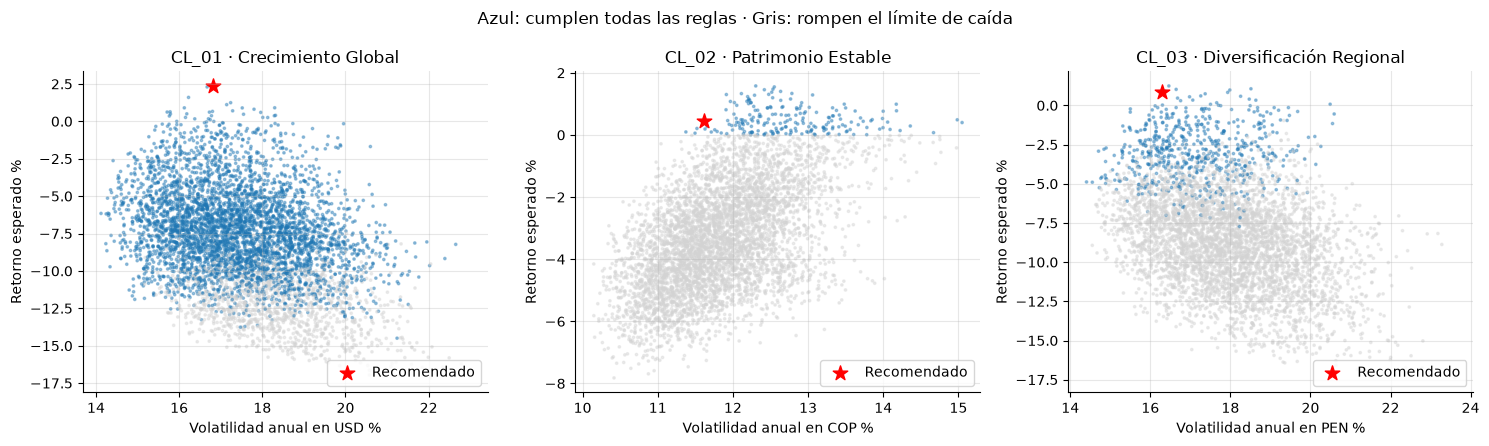

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (cid, r) in zip(axes, results.items()):
    cl = r['cloud']
    ax.scatter(cl.vol * 100, cl.retorno_esperado * 100, s=3, c=np.where(cl.factible, 'tab:blue', 'lightgrey'), alpha=.4)
    ax.scatter(r['best'].vol * 100, r['best'].retorno_esperado * 100, s=120, c='red', marker='*', label='Recomendado')
    ax.set_title(f"{cid} · {clients.loc[cid, 'profile_name']}")
    ax.set_xlabel(f"Volatilidad anual en {RULES[cid]['currency']} %"); ax.set_ylabel('Retorno esperado %')
    ax.legend(loc='lower right')
plt.suptitle('Azul: cumplen todas las reglas · Gris: rompen el límite de caída'); plt.tight_layout()

## 7. Comportamiento histórico en la moneda del cliente
Comparación con un portafolio de igual peso, que es la alternativa ingenua.

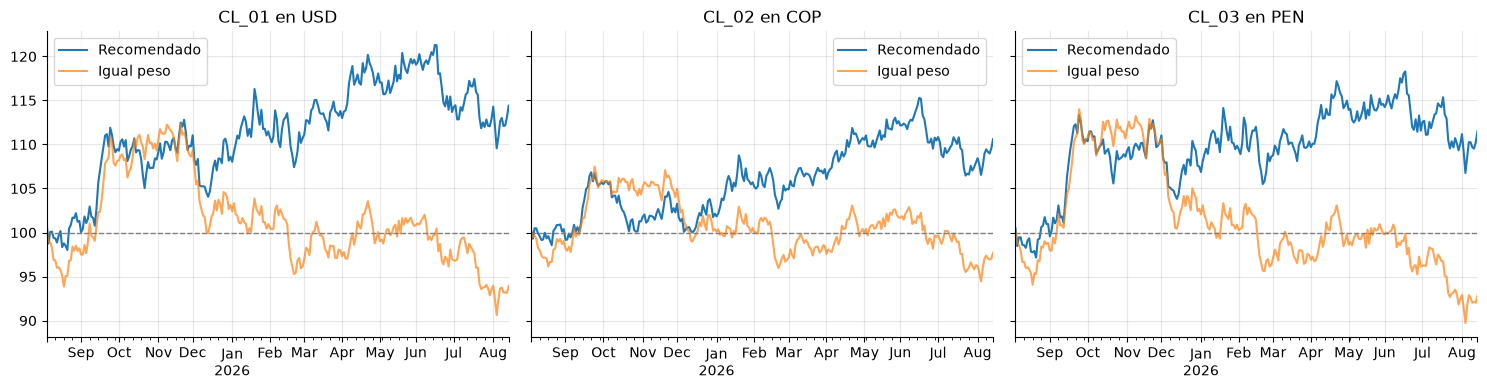

In [10]:
def path(cid, w):
    R = local_returns(RULES[cid]['currency'])
    pr = R[w.index] @ w.values
    return (1 + pr).cumprod() * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
ew = pd.Series(1 / 8, ASSETS)
for ax, (cid, r) in zip(axes, results.items()):
    path(cid, r['w']).plot(ax=ax, label='Recomendado')
    cash = RULES[cid].get('cash', 0.0)
    path(cid, ew * (1 - cash)).plot(ax=ax, label='Igual peso', alpha=.7)
    ax.axhline(100, color='grey', ls='--', lw=1)
    ax.set_title(f"{cid} en {RULES[cid]['currency']}"); ax.legend(); ax.set_xlabel('')
plt.tight_layout()

## 8. Robustez: ¿y si el próximo año no se parece al pasado?
Se simulan 2,000 años posibles armando bloques de 20 días tomados al azar de la historia (bootstrap por bloques, que conserva rachas y correlaciones). Para cada recomendación se mide la probabilidad de superar el límite de caída del cliente.

In [11]:
def block_bootstrap_dd(cid, w, n_paths=2000, horizon=252, block=20):
    R = local_returns(RULES[cid]['currency'])[w.index].values @ w.values
    T = len(R)
    starts = rng.integers(0, T - block, size=(n_paths, horizon // block + 1))
    sims = np.stack([np.concatenate([R[s:s + block] for s in row])[:horizon] for row in starts])
    curve = np.cumprod(1 + sims, axis=1)
    dd = (curve / np.maximum.accumulate(curve, axis=1) - 1).min(axis=1)
    return dd, curve[:, -1] - 1

rob = {}
for cid, r in results.items():
    cash = RULES[cid].get('cash', 0.0)
    dd_rec, ret_rec = block_bootstrap_dd(cid, r['w'])
    dd_ew, _ = block_bootstrap_dd(cid, ew * (1 - cash))
    lim = RULES[cid]['dd_limit']
    rob[cid] = {
        'P(caída > límite) recomendado %': (np.abs(dd_rec) > lim).mean() * 100,
        'P(caída > límite) igual peso %': (np.abs(dd_ew) > lim).mean() * 100,
        'caída mediana %': np.median(dd_rec) * 100,
        'caída p95 %': np.quantile(dd_rec, 0.05) * 100,
        'P(pérdida en el año) %': (ret_rec < 0).mean() * 100,
    }
pd.DataFrame(rob).T.round(1)

,P(caída > límite) recomendado %,P(caída > límite) igual peso %,caída mediana %,caída p95 %,P(pérdida en el año) %
CL_01,1.6,22.6,-10.6,-18.6,16.2
CL_02,31.8,67.0,-8.5,-15.1,21.0
CL_03,17.0,65.8,-11.0,-18.4,20.4


El bootstrap reutiliza los mismos 271 días, así que no inventa escenarios nuevos (por ejemplo, el shock de tasas del twist). Por eso se complementa con la prueba del twist de la sección 5.

## 9. Sensibilidad a los supuestos
¿Cambia la recomendación si somos más o menos optimistas con los ganadores del año, o si el shock de tasas pega más fuerte?

In [12]:
base_mu, base_shrink, base_rate = mu.copy(), SHRINK, RATE_PCT_PER_POINT
rows = []
for shrink in (0.25, 0.5, 0.75):
    for rate_pp in (0.0, 0.03, 0.06):
        mu = shrink * hist_ret + (1 - shrink) * hist_ret.mean() + RATE_SCALE * rate_pp
        try:
            w, best, _, _ = recommend('CL_02', RULES['CL_02'], n=150000)
        except ValueError:
            rows.append({'peso_histórico': shrink, 'shock_tasas_por_punto': rate_pp,
                         'portafolio_CL_02': 'Sin solución: ningún portafolio de acciones tiene retorno esperado ≥ 0',
                         'caída_máx_%': np.nan})
            continue
        top = w[w > 0].sort_values(ascending=False)
        rows.append({'peso_histórico': shrink, 'shock_tasas_por_punto': rate_pp,
                     'portafolio_CL_02': ', '.join(f'{a[3:]} {v:.0%}' for a, v in top.items()),
                     'caída_máx_%': round(best['caída_máx'] * 100, 1)})
mu, SHRINK, RATE_PCT_PER_POINT = base_mu, base_shrink, base_rate
pd.DataFrame(rows)

,peso_histórico,shock_tasas_por_punto,portafolio_CL_02,caída_máx_%
0,0.25,0.00,Sin solución: ningún portafolio de acciones ti...,NaN
1,0.25,0.03,Sin solución: ningún portafolio de acciones ti...,NaN
2,0.25,0.06,Sin solución: ningún portafolio de acciones ti...,NaN
3,0.50,0.00,"A01 25%, A05 25%, A04 10%, A08 10%",-8.3
4,0.50,0.03,"A04 25%, A05 20%, A01 15%, A02 5%, A08 5%",-7.7
5,0.50,0.06,"A04 25%, A05 25%, A01 20%",-7.9
6,0.75,0.00,"A01 25%, A05 25%, A08 10%, A02 5%, A06 5%",-9.4
7,0.75,0.03,"A01 25%, A05 25%, A04 10%, A02 5%, A08 5%",-8.5
8,0.75,0.06,"A05 25%, A01 20%, A04 15%, A06 5%, A08 5%",-7.4


Lo que se mantiene en todas las combinaciones es el núcleo **A05 + A04 + A01**, con A08 y A02 en pesos bajos. Los pesos exactos cambian entre corridas porque hay muchos portafolios casi equivalentes: no hay que defender un 20% contra un 25%, sino el núcleo.

Con poco peso en la historia (25%), ningún portafolio de acciones tiene retorno esperado positivo para CL_02: la recomendación depende de creer, al menos en parte, que A04 y A05 siguen siendo mejores que el resto.

## 10. Exportar las recomendaciones para la presentación

In [13]:
rec_rows = []
for cid, r in results.items():
    for a, v in weights[cid].items():
        if v > 0:
            rec_rows.append({'client_id': cid, 'profile_name': clients.loc[cid, 'profile_name'], 'asset_id': a,
                             'name': names[a], 'weight_pct': round(v * 100)})
recs = pd.DataFrame(rec_rows)
recs.to_csv(CLEAN / 'recommendations.csv', index=False)
summary.round(2).rename_axis('client_id').reset_index().to_csv(CLEAN / 'recommendation_metrics.csv', index=False)
pd.DataFrame(rob).T.round(1).rename_axis('client_id').reset_index().to_csv(CLEAN / 'recommendation_robustness.csv', index=False)
recs

,client_id,profile_name,asset_id,name,weight_pct
0,CL_01,Crecimiento Global,VF_A01,Andes Consumer,20
1,CL_01,Crecimiento Global,VF_A04,Lima Financial,35
2,CL_01,Crecimiento Global,VF_A05,Aurora Health,35
3,CL_01,Crecimiento Global,VF_A06,Norte Industrials,5
4,CL_01,Crecimiento Global,VF_A07,Sierra Materials,5
5,CL_02,Patrimonio Estable,VF_A01,Andes Consumer,10
6,CL_02,Patrimonio Estable,VF_A04,Lima Financial,20
7,CL_02,Patrimonio Estable,VF_A05,Aurora Health,25
8,CL_02,Patrimonio Estable,VF_A07,Sierra Materials,5
9,CL_02,Patrimonio Estable,VF_A08,Atlas Utilities,10


## 11. Decisión que defendemos

**Cliente foco: CL_02 · Patrimonio Estable**, porque es el único al que le pegan los tres cambios del twist y donde la decisión cambia más.

1. **Separar el portafolio en dos partes.** 30% en efectivo o depósito en COP para el retiro en 6 meses, y 70% invertido.
2. **Asegurar la ganancia cambiaria.** El COP se depreció 8%: el 70% en USD ya vale más en pesos, y el 30% que se va a retirar se convierte hoy para no perder esa ganancia si el COP se recupera.
3. **En la parte invertida, priorizar los activos que resistieron y limitar a los sensibles a tasas.** Poca exposición a alta volatilidad (dentro del 25% permitido) y A08 con un máximo de 10%, menos de lo que tendría en un portafolio "defensivo" clásico.
4. **Evidencia:** cumple el límite de caída de 10% en COP en el histórico, en el bootstrap tiene menos de la mitad de probabilidad de superarlo que la alternativa de igual peso, y el twist le resulta positivo por la depreciación del COP.

**Lo que no sabemos:**
- El efecto real del shock de tasas (está muy fuera de la historia).
- Si A04 y A05 seguirán liderando: si confiamos menos en el retorno histórico (peso 25%), ningún portafolio de acciones tiene retorno esperado positivo para CL_02 (sección 9). Es otro argumento para la parte de liquidez.
- Aun el portafolio recomendado tiene una probabilidad relevante de superar la caída de 10% en el bootstrap.

Por eso el retorno esperado está encogido, hay topes por activo y el portafolio debe revisarse cuando haya precios posteriores al twist.